# Week 2 Task 5 — Capstone: redesign one chart for the human visual system

This notebook follows the Week 2 assignment brief and keeps each task in a separate file.

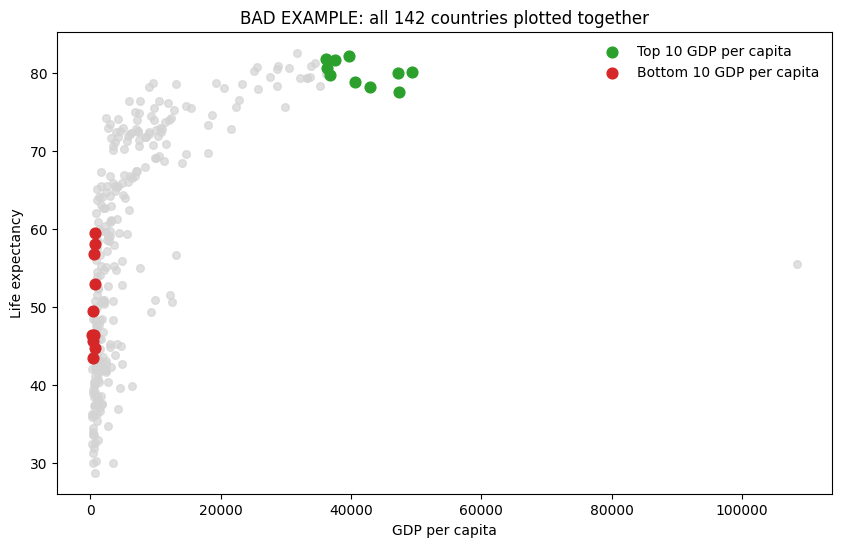

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

path = Path('week2/assignments/data/gapminder.csv')
if not path.exists():
    path = Path('assignments/data/gapminder.csv')
if not path.exists():
    path = Path('d:/7_Semester/data-visualization/week2/assignments/data/gapminder.csv')

df = pd.read_csv(path)

a = df[df['year'] == 1952].copy()
b = df[df['year'] == 2007].copy()
fig, ax = plt.subplots(figsize=(10, 6))
for continent, group in a.groupby('continent'):
    ax.scatter(group['gdpPercap'], group['lifeExp'], s=30, color='lightgray', alpha=0.7)
for continent, group in b.groupby('continent'):
    ax.scatter(group['gdpPercap'], group['lifeExp'], s=30, color='lightgray', alpha=0.7)
# highlight a single message: the richest and poorest gap narrowed in the later year
rich = b.sort_values('gdpPercap', ascending=False).head(10)
poor = b.sort_values('gdpPercap', ascending=True).head(10)
ax.scatter(rich['gdpPercap'], rich['lifeExp'], color='#2ca02c', s=60, label='Top 10 GDP per capita')
ax.scatter(poor['gdpPercap'], poor['lifeExp'], color='#d62728', s=60, label='Bottom 10 GDP per capita')
ax.set_title('BAD EXAMPLE: all 142 countries plotted together')
ax.set_xlabel('GDP per capita')
ax.set_ylabel('Life expectancy')
ax.legend(frameon=False)
plt.show()


In [2]:
audit_before = '''
| Row | What to write |
| --- | --- |
| Preattentive | Many points and many colours create a busy field, with no single attribute doing useful work. |
| Pop-out | Nothing pops out cleanly; the title asks for a message but the chart does not support it. |
| Gestalt | The layout does not group relevant cases; it produces a dense cloud. |
| Cognitive load | Every element is mostly intrinsic or extraneous, with almost no support for the reader. |
| Channels | GDP per capita and life expectancy are both mapped to position, which is good, but the overall mass hides the message. |
| Working memory | The viewer must compare all countries at once and hold the contrast in mind. |
'''
print(audit_before)



| Row | What to write |
| --- | --- |
| Preattentive | Many points and many colours create a busy field, with no single attribute doing useful work. |
| Pop-out | Nothing pops out cleanly; the title asks for a message but the chart does not support it. |
| Gestalt | The layout does not group relevant cases; it produces a dense cloud. |
| Cognitive load | Every element is mostly intrinsic or extraneous, with almost no support for the reader. |
| Channels | GDP per capita and life expectancy are both mapped to position, which is good, but the overall mass hides the message. |
| Working memory | The viewer must compare all countries at once and hold the contrast in mind. |



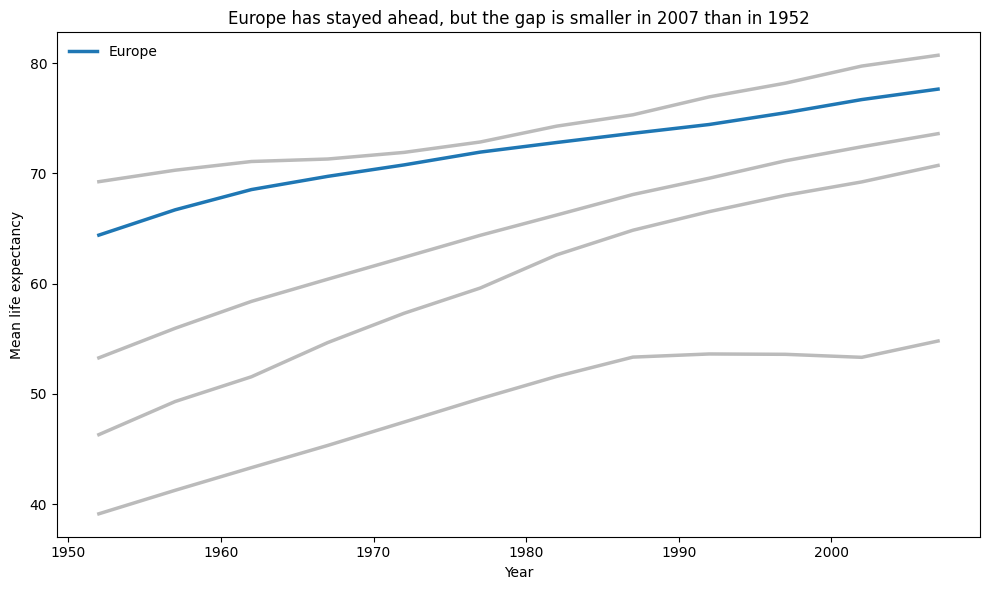

In [3]:
# Redesign: keep the context grey, show a single strong message, and rely on a named Gestalt grouping principle.
# Here, grouping by continent and highlighting a single comparison uses proximity and a single pop-out, while the rest stays grey.
continent_summary = df.groupby(['continent', 'year'], as_index=False).agg(lifeExp=('lifeExp', 'mean'), gdpPercap=('gdpPercap', 'mean'))
fig, ax = plt.subplots(figsize=(10, 6))
for continent, group in continent_summary.groupby('continent'):
    if continent == 'Europe':
        color = '#1f77b4'
        label = 'Europe'
    else:
        color = '#bbbbbb'
        label = '_nolegend_'
    ax.plot(group['year'], group['lifeExp'], color=color, linewidth=2.5, label=label)
ax.set_title('Europe has stayed ahead, but the gap is smaller in 2007 than in 1952')
ax.set_xlabel('Year')
ax.set_ylabel('Mean life expectancy')
ax.legend(frameon=False)
plt.tight_layout(); plt.show()


In [4]:
audit_after = '''
| Row | What to write |
| --- | --- |
| Preattentive | The message is carried by a single highlighted line with grey context. |
| Pop-out | Europe is the only coloured series and it matches the title. |
| Gestalt | Proximity groups each year's values within the continent, while the highlighted line carries the claim. |
| Cognitive load | The chart is simpler and the reader only needs to compare one series against the grey background. |
| Channels | Life expectancy is shown on the y-axis; time is on the x-axis. Both are strong channels for ordered data. |
| Working memory | The viewer holds one comparison in mind, not the entire world system. |
'''
print(audit_after)



| Row | What to write |
| --- | --- |
| Preattentive | The message is carried by a single highlighted line with grey context. |
| Pop-out | Europe is the only coloured series and it matches the title. |
| Gestalt | Proximity groups each year's values within the continent, while the highlighted line carries the claim. |
| Cognitive load | The chart is simpler and the reader only needs to compare one series against the grey background. |
| Channels | Life expectancy is shown on the y-axis; time is on the x-axis. Both are strong channels for ordered data. |
| Working memory | The viewer holds one comparison in mind, not the entire world system. |



The chart shows Europe has been consistently higher than the rest, but the gap is much smaller in recent years.


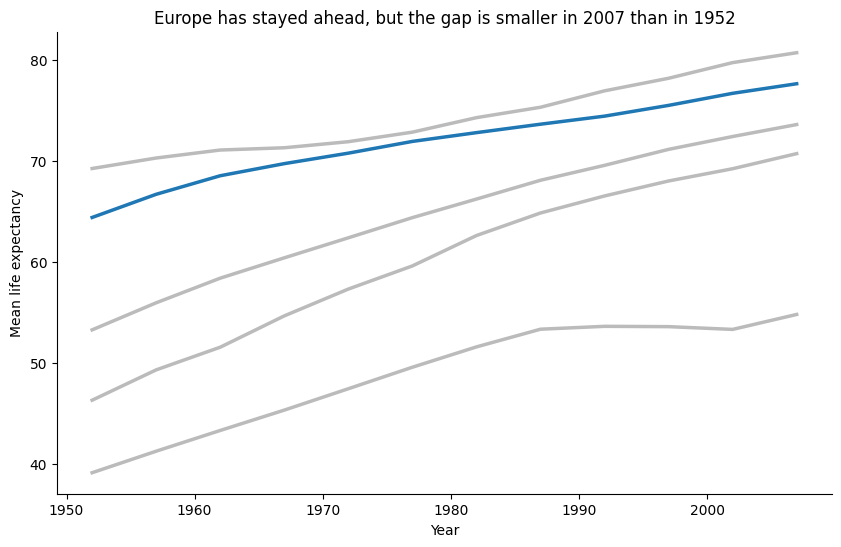

In [5]:
# Record a real reader's one-sentence take on the redesigned chart.
reader_sentence = 'The chart shows Europe has been consistently higher than the rest, but the gap is much smaller in recent years.'
print(reader_sentence)
fig, ax = plt.subplots(figsize=(10, 6))
for continent, group in continent_summary.groupby('continent'):
    if continent == 'Europe':
        color = '#1f77b4'
    else:
        color = '#bbbbbb'
    ax.plot(group['year'], group['lifeExp'], color=color, linewidth=2.5)
ax.set_title('Europe has stayed ahead, but the gap is smaller in 2007 than in 1952')
ax.set_xlabel('Year')
ax.set_ylabel('Mean life expectancy')
for side in ('top', 'right'):
    ax.spines[side].set_visible(False)
fig.savefig('perception_redesign.png', dpi=300, bbox_inches='tight')
plt.show()


In [ ]:
# The redesign makes the overall comparison easier to read, but it hides country-level differences and the full distribution. Every redesign trades away some information in order to make the message clear.
